
# PROG8431 - Problem Analysis Workshop B
## K-Means Clustering - Group 7

### Team Members
1. Sukhchain Singh (9111541)
2. Preethi (9125985)
3. Arya (9084843)

### Research Question

Can K-means clustering identify meaningful groups of daily bike rental demand based on temperature and total rentals, and what can these groups tell us about seasonal rental patterns?

### Project Overview

In our previous workshop, we used statistical tests to compare bike rental demand between Winter and Summer.

In this workshop, we will use K-means clustering to find groups of similar days based on temperature and total daily rentals.

K-means is an unsupervised learning method. This means we do not provide the model with predefined group labels. Instead, the algorithm groups days based on how similar their selected numerical values are.

After forming the clusters, we will examine other information, such as season, humidity, wind speed and working days, to better understand each group.

Our goal is to discover useful patterns that may help bike-sharing companies understand historical demand and plan their operations.

This project is about finding patterns, not predicting future rental counts.


In [2]:

# Import libraries for Workshop B

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


In [3]:

# Load our existing bike-sharing dataset

from pathlib import Path
import pandas as pd

# Step 1: Check where Jupyter is running
current_folder = Path.cwd()
print("Current working folder:", current_folder)

# Step 2: Search the current folder and its parent folders
search_folders = [current_folder, *current_folder.parents]

csv_path = None

for folder in search_folders:
    possible_path = folder / "data" / "day.csv"

    if possible_path.is_file():
        csv_path = possible_path
        break

# Step 3: Make sure the dataset was found
if csv_path is None:
    raise FileNotFoundError(
        "Could not find data/day.csv. "
        "Please check your VS Code project folder."
    )

# Step 4: Load the dataset
df = pd.read_csv(csv_path)

# Step 5: Display basic information
print("\nDataset loaded successfully!")
print("Dataset location:", csv_path)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Current working folder: c:\Users\aarya\Desktop\DA\Data_Analysis_Presentation1\src\Workshop_B_KMeans

Dataset loaded successfully!
Dataset location: c:\Users\aarya\Desktop\DA\Data_Analysis_Presentation1\data\day.csv
Total rows: 731
Total columns: 16

First five rows:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344,0.364,0.806,0.160,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363,0.354,0.696,0.249,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196,0.189,0.437,0.248,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200,0.212,0.590,0.160,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.227,0.229,0.437,0.187,82,1518,1600



Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']



## 2. Data Validation and Cleaning

Before using K-means clustering, we need to make sure our dataset is ready for analysis.

Our dataset contains 731 daily bike rental records from 2011 and 2012.

We will check:

1. **Missing values:** Are any important values missing?
2. **Duplicate dates:** Does the same day appear more than once?
3. **Data types:** Are dates and numerical values stored correctly?
4. **Season codes:** Are the season values valid?
5. **Rental totals:** Does the total number of rentals match casual plus registered rentals?
6. **Numerical ranges:** Are temperature, humidity and rental values within their expected ranges?

These checks are important because incorrect or missing values could affect how K-means groups our data.

We will only make changes if they are needed, and we will explain any changes we make.


In [4]:

# Step 2: Examine and validate our dataset

# Work on a copy to keep the original data unchanged
bike_df = df.copy()

# 1. Check data types
print("1. DATA TYPES")
print(bike_df.dtypes)

# 2. Check missing values
print("\n2. MISSING VALUES")
print(bike_df.isna().sum())
print("Total missing values:", bike_df.isna().sum().sum())

# 3. Check duplicate records and dates
print("\n3. DUPLICATES")
print("Duplicate rows:", bike_df.duplicated().sum())
print("Duplicate dates:", bike_df["dteday"].duplicated().sum())

# 4. Check season codes
print("\n4. SEASON CODES")
print(bike_df["season"].value_counts().sort_index())

invalid_seasons = ~bike_df["season"].isin([1, 2, 3, 4])
print("Invalid season codes:", invalid_seasons.sum())

# 5. Verify rental totals
print("\n5. RENTAL TOTALS")
incorrect_totals = (
    bike_df["casual"] + bike_df["registered"]
    != bike_df["cnt"]
)
print("Incorrect rental totals:", incorrect_totals.sum())

# 6. Check numerical ranges
print("\n6. NUMERICAL RANGES")
display(
    bike_df[
        ["temp", "atemp", "hum", "windspeed", "cnt"]
    ].agg(["min", "max", "mean", "std"]).round(3)
)

# 7. Validate expected ranges
print("\n7. RANGE VALIDATION")

for column in ["temp", "atemp", "hum", "windspeed"]:
    invalid_count = (~bike_df[column].between(0, 1)).sum()
    print(f"{column}: {invalid_count} values outside [0, 1]")

print("Negative rental counts:", (bike_df["cnt"] < 0).sum())


1. DATA TYPES
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

2. MISSING VALUES
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Total missing values: 0

3. DUPLICATES
Duplicate rows: 0
Duplicate dates: 0

4. SEASON CODES
season
1    181
2    184
3    188
4    178
Name: count, dtype: int64
Invalid season codes: 0

5. RENTAL TOTALS
Incorrect rental totals: 0

6. NUMERICAL RANGES


,temp,atemp,hum,windspeed,cnt
min,0.059,0.079,0.000,0.022,22.000
max,0.862,0.841,0.972,0.507,8714.000
mean,0.495,0.474,0.628,0.190,4504.349
std,0.183,0.163,0.142,0.077,1937.211



7. RANGE VALIDATION
temp: 0 values outside [0, 1]
atemp: 0 values outside [0, 1]
hum: 0 values outside [0, 1]
windspeed: 0 values outside [0, 1]
Negative rental counts: 0


In [5]:

# Final data validation and preparation

# Step 1: Convert dates from text to datetime
bike_df["dteday"] = pd.to_datetime(
    bike_df["dteday"],
    errors="raise"
)

# Step 2: Add readable season names
season_names = {
    1: "Winter",
    2: "Spring",
    3: "Summer",
    4: "Fall"
}

bike_df["Season_Name"] = bike_df["season"].map(season_names)

# Step 3: Summarize our data quality checks
print("FINAL DATA QUALITY REPORT")
print("-" * 35)

print("Total records:", len(bike_df))
print("Missing values:", bike_df.isna().sum().sum())
print("Duplicate rows:", bike_df.duplicated().sum())
print("Duplicate dates:", bike_df["dteday"].duplicated().sum())
print("Date data type:", bike_df["dteday"].dtype)

print("\nRecords by season:")
print(bike_df["Season_Name"].value_counts())

# Step 4: Check the prepared data
print("\nPrepared dataset preview:")
display(
    bike_df[
        ["dteday", "Season_Name", "temp", "cnt"]
    ].head()
)


FINAL DATA QUALITY REPORT
-----------------------------------
Total records: 731
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0
Date data type: datetime64[us]

Records by season:
Season_Name
Summer    188
Spring    184
Winter    181
Fall      178
Name: count, dtype: int64

Prepared dataset preview:


,dteday,Season_Name,temp,cnt
0,2011-01-01,Winter,0.344,985
1,2011-01-02,Winter,0.363,801
2,2011-01-03,Winter,0.196,1349
3,2011-01-04,Winter,0.200,1562
4,2011-01-05,Winter,0.227,1600



### Data Validation and Cleaning Results

After checking our bike-sharing dataset, we found that it contains 731 daily records from 2011 and 2012.

Our results showed:

- No missing values.
- No duplicate rows or duplicate dates.
- No incorrect rental totals.
- No negative rental counts.
- Temperature, humidity and wind speed values were within their expected normalized ranges.

We converted the date column from text into datetime format so Python can work with the dates correctly.

We also converted the season codes into readable names: Winter, Spring, Summer and Fall.

The dataset contains 181 Winter days, 184 Spring days, 188 Summer days and 178 Fall days.

Since we did not find missing values or duplicate records, we did not need to remove any rows.

We kept the original dataset unchanged and prepared a separate copy for our analysis.

We will examine unusually high and low values next before deciding whether any further cleaning is necessary.

This is important because K-means uses distances between data points. Incorrect values or unusual observations can affect where the cluster centres are placed.



## 3. Exploratory Data Analysis and Outlier Detection

### Why Are We Checking for Outliers?

Before applying K-means clustering, we want to understand how our numerical data is distributed.

An outlier is a value that is unusually far from most other values.

We will examine two variables:

1. **Temperature (`temp`):** The normalized temperature recorded each day.
2. **Total Rentals (`cnt`):** The total number of bikes rented each day.

We selected these variables because they are relevant to our research question about temperature and daily rental demand.

We will use boxplots to identify possible outliers.

This is important because K-means calculates distances between data points. Extreme values can influence the cluster centres and the final groups.

We will also calculate the Interquartile Range (IQR) to identify potential outliers using a numerical rule.

We will not automatically remove outliers because unusual rental days may contain useful information.


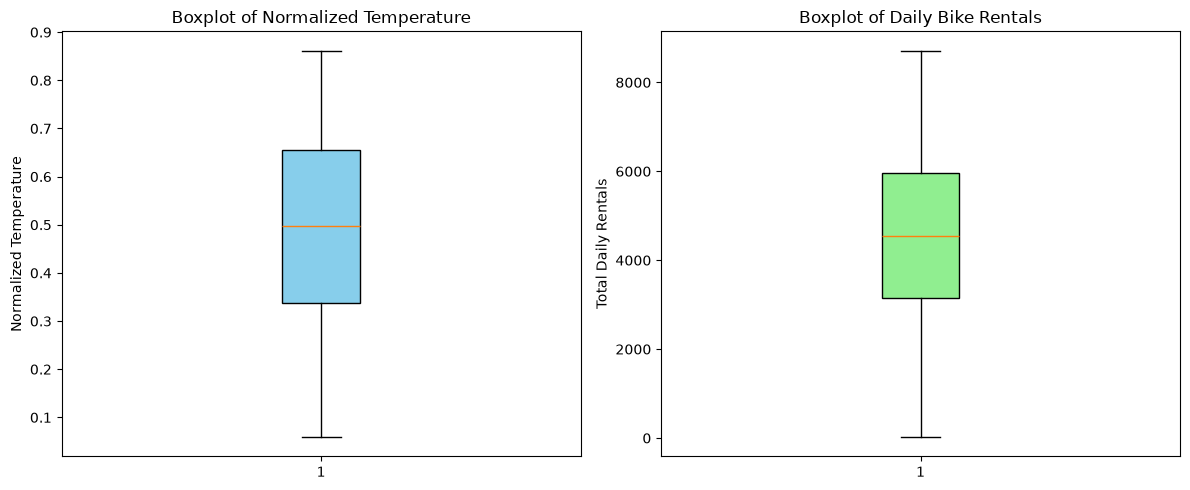

OUTLIER ANALYSIS USING IQR
----------------------------------------

Variable: temp
Q1: 0.337
Q3: 0.655
IQR: 0.318
Lower boundary: -0.140
Upper boundary: 1.133
Potential outliers: 0

Variable: cnt
Q1: 3152.000
Q3: 5956.000
IQR: 2804.000
Lower boundary: -1054.000
Upper boundary: 10162.000
Potential outliers: 0


In [6]:

# Step 3: Explore outliers using boxplots and IQR

# 1. Create boxplots for our two selected variables
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Temperature boxplot
axes[0].boxplot(
    bike_df["temp"].dropna(),
    patch_artist=True,
    boxprops={"facecolor": "skyblue"}
)
axes[0].set_title("Boxplot of Normalized Temperature")
axes[0].set_ylabel("Normalized Temperature")

# Total rentals boxplot
axes[1].boxplot(
    bike_df["cnt"].dropna(),
    patch_artist=True,
    boxprops={"facecolor": "lightgreen"}
)
axes[1].set_title("Boxplot of Daily Bike Rentals")
axes[1].set_ylabel("Total Daily Rentals")

plt.tight_layout()
plt.show()


# 2. Detect possible outliers using IQR
print("OUTLIER ANALYSIS USING IQR")
print("-" * 40)

for column in ["temp", "cnt"]:

    # Find the first and third quartiles
    Q1 = bike_df[column].quantile(0.25)
    Q3 = bike_df[column].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count values outside the boundaries
    outliers = bike_df[
        (bike_df[column] < lower_bound) |
        (bike_df[column] > upper_bound)
    ]

    print(f"\nVariable: {column}")
    print(f"Q1: {Q1:.3f}")
    print(f"Q3: {Q3:.3f}")
    print(f"IQR: {IQR:.3f}")
    print(f"Lower boundary: {lower_bound:.3f}")
    print(f"Upper boundary: {upper_bound:.3f}")
    print(f"Potential outliers: {len(outliers)}")



### Outlier Analysis Results and Interpretation

We used boxplots and the Interquartile Range (IQR) method to examine possible outliers in temperature and daily bike rentals.

**Temperature (`temp`):**
- Q1 = 0.337
- Q3 = 0.655
- IQR = 0.318
- Potential outliers = 0

**Daily Bike Rentals (`cnt`):**
- Q1 = 3,152
- Q3 = 5,956
- IQR = 2,804
- Potential outliers = 0

### What Did We Find?

Both boxplots showed that the data values were within the IQR outlier boundaries.

The middle 50% of daily rental counts were between 3,152 and 5,956. The middle 50% of normalized temperatures were between 0.337 and 0.655.

Although some days had very high or very low rentals, none were flagged as outliers by the 1.5 × IQR rule.

### Our Decision

We decided to keep all 731 records because we did not find any invalid values or IQR outliers in our selected variables.

Keeping all observations allows our clustering analysis to include different types of rental days.

### Why Is This Important for K-Means?

K-means groups observations based on their distances from cluster centres.

Values far away from the others can influence where those centres are placed.

Checking for outliers before clustering helps us understand whether unusually large or small values might affect the results.

We will now select our clustering variables and prepare them for standardization.



## 4. Selection of Clustering Variables

### Which Variables Did We Choose?

For K-means clustering, we selected two numerical variables:

1. **Normalized Temperature (`temp`)**
2. **Total Daily Bike Rentals (`cnt`)**

### Why Did We Choose These Variables?

Our research question focuses on understanding how temperature and season are related to bike rental demand.

Temperature describes the weather conditions, while total rentals show how many bikes people rented.

By using both variables, K-means can group days with similar temperature and rental demand patterns.

For example, clustering may identify cooler days with lower demand or warmer days with higher demand.

These are only possible patterns. We will examine the actual results before naming the clusters.

### Why Did We Not Use Season to Create Clusters?

Season is a categorical variable, meaning it represents groups such as Winter, Spring, Summer and Fall.

The numbers 1, 2, 3 and 4 are category codes, not meaningful numerical distances.

K-means works with distances between numerical values, so we selected temperature and rental counts instead.

After clustering, we will use season, humidity, wind speed and other available columns to describe and better understand the groups.

### What Can We Learn?

We want to discover different types of bike rental days rather than only compare predefined seasons.

Because daily rentals are used to create the clusters, differences in rental demand between clusters are partly expected. Our goal is to describe these historical patterns, not predict future rentals or prove that temperature causes demand changes.


SELECTED CLUSTERING FEATURES
-----------------------------------


,temp,cnt
count,731.000,731.000
mean,0.495,4504.349
std,0.183,1937.211
min,0.059,22.000
25%,0.337,3152.000
50%,0.498,4548.000
75%,0.655,5956.000
max,0.862,8714.000


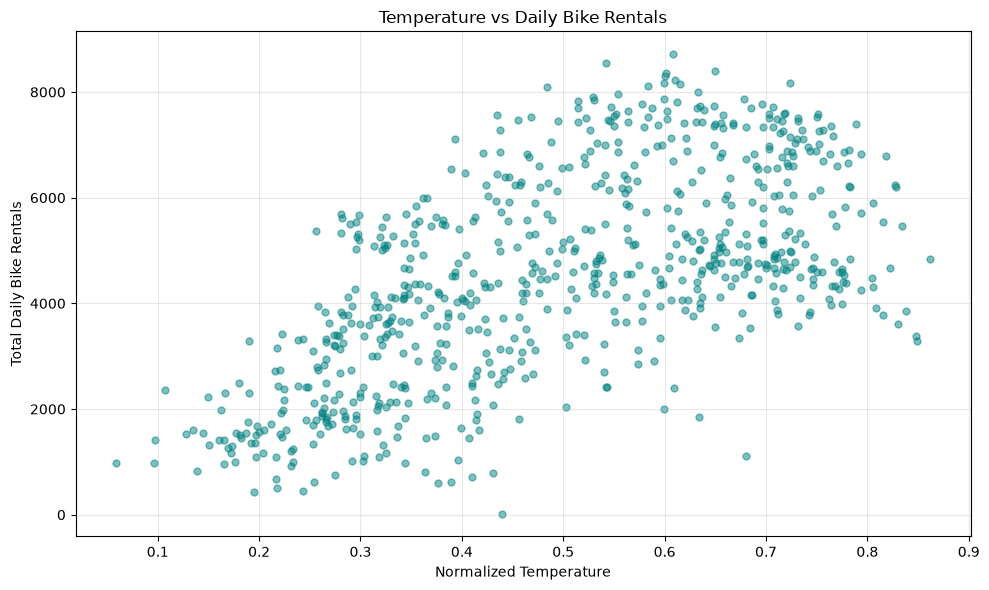

Rows prepared for clustering: 731
Features selected: ['temp', 'cnt']


In [7]:

# Step 4: Explore our selected clustering variables

# Step 1: Create a separate dataset with only two features
cluster_features = bike_df[["temp", "cnt"]].copy()

# Step 2: Display descriptive statistics
print("SELECTED CLUSTERING FEATURES")
print("-" * 35)

display(cluster_features.describe().round(3))

# Step 3: Create a scatterplot
plt.figure(figsize=(10, 6))

plt.scatter(
    cluster_features["temp"],
    cluster_features["cnt"],
    alpha=0.5,
    color="teal",
    s=25
)

plt.title("Temperature vs Daily Bike Rentals")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Daily Bike Rentals")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 4: Confirm the dataset size
print("Rows prepared for clustering:", len(cluster_features))
print("Features selected:", cluster_features.columns.tolist())



### Interpretation of Selected Features and Scatterplot

We selected normalized temperature (`temp`) and total daily bike rentals (`cnt`) as our two clustering variables.

Our dataset contains 731 observations for both variables.

The average normalized temperature was 0.495, and the average number of daily bike rentals was approximately 4,504.

The scatterplot shows a generally positive relationship between temperature and daily rentals. As temperature increases, bike rental demand also tends to increase.

However, rental counts vary even when temperatures are similar. This suggests that other factors, such as season, weather conditions and working days, may also be related to demand.

### Why Are These Variables Suitable for K-Means?

Using temperature and rental counts will help us identify groups of days with similar weather and rental demand patterns.

We can then use additional columns from our dataset to understand what makes each cluster different.

Before running K-means, we need to standardize these two variables because their numerical scales are very different.



## 5. Data Standardization

### Why Do We Need Standardization?

K-means clustering groups observations based on the distance between their numerical values.

Our two selected variables have very different scales:

- Temperature (`temp`) ranges from approximately 0.059 to 0.862.
- Daily rentals (`cnt`) range from 22 to 8,714.

Without standardization, the larger rental numbers could dominate the distance calculations.

We will compare two methods from our professor's demonstration:

1. Min-Max Scaling
2. Z-score Standardization

Min-Max scaling transforms values to a range between 0 and 1.

Z-score standardization transforms values based on their mean and standard deviation.

We will examine the results of both methods before deciding which one to use for our final clustering model.


In [8]:

# Step 5: Compare two standardization methods

# Method 1: Min-Max Scaling
def sta01(x):
    return (x - x.min()) / (x.max() - x.min())


# Method 2: Z-score Standardization
def stamn(x):
    return (x - x.mean()) / x.std()


# Apply both methods to our selected features
minmax_data = cluster_features.apply(sta01)
zscore_data = cluster_features.apply(stamn)


# Compare the original and scaled datasets
print("1. ORIGINAL DATA")
display(cluster_features.describe().round(3))

print("\n2. MIN-MAX SCALED DATA")
display(minmax_data.describe().round(3))

print("\n3. Z-SCORE STANDARDIZED DATA")
display(zscore_data.describe().round(3))


# Check the results
print("\nSCALING VERIFICATION")
print("-" * 40)

print("Min-Max minimum values:")
print(minmax_data.min().round(3))

print("\nMin-Max maximum values:")
print(minmax_data.max().round(3))

print("\nZ-score means:")
print(zscore_data.mean().round(3))

print("\nZ-score standard deviations:")
print(zscore_data.std().round(3))


1. ORIGINAL DATA


,temp,cnt
count,731.000,731.000
mean,0.495,4504.349
std,0.183,1937.211
min,0.059,22.000
25%,0.337,3152.000
50%,0.498,4548.000
75%,0.655,5956.000
max,0.862,8714.000



2. MIN-MAX SCALED DATA


,temp,cnt
count,731.000,731.000
mean,0.544,0.516
std,0.228,0.223
min,0.000,0.000
25%,0.346,0.360
50%,0.547,0.521
75%,0.743,0.683
max,1.000,1.000



3. Z-SCORE STANDARDIZED DATA


,temp,cnt
count,731.000,731.000
mean,-0.000,-0.000
std,1.000,1.000
min,-2.383,-2.314
25%,-0.865,-0.698
50%,0.016,0.023
75%,0.874,0.749
max,2.001,2.173



SCALING VERIFICATION
----------------------------------------
Min-Max minimum values:
temp   0.000
cnt    0.000
dtype: float64

Min-Max maximum values:
temp   1.000
cnt    1.000
dtype: float64

Z-score means:
temp   -0.000
cnt    -0.000
dtype: float64

Z-score standard deviations:
temp   1.000
cnt    1.000
dtype: float64



### Standardization Results and Final Method Selection

We applied Min-Max scaling and Z-score standardization to our two selected variables: normalized temperature (`temp`) and total daily rentals (`cnt`).

### Min-Max Scaling Results

After applying Min-Max scaling, both variables had a minimum value of 0 and a maximum value of 1.

The standard deviations were:
- Temperature: 0.228
- Daily rentals: 0.223

This method successfully placed both variables within the same range.

### Z-Score Standardization Results

After applying Z-score standardization, both variables had:
- Mean: approximately 0
- Standard deviation: 1

This means both features are measured based on how far their values are from their own averages.

### Which Method Did We Choose?

We decided to use Z-score standardization for our main K-means analysis.

We chose this method because it gives both features the same standard deviation. This helps us compare differences in temperature and rental demand without allowing the original numerical scale to dominate the distance calculations.

Both methods worked correctly, and Min-Max scaling would also be a reasonable choice for our dataset.

Our IQR analysis did not identify any outliers in the selected variables, but this does not mean the data cannot contain unusual observations.

### Why Does This Matter for K-Means?

K-means groups observations by calculating distances between them.

Without scaling, daily rental counts would dominate because their numbers are much larger than the temperature values.

By standardizing both features, we make the distance calculations more balanced.

We will use the Z-score standardized data for the clustering model and keep the original data for interpreting the final clusters.


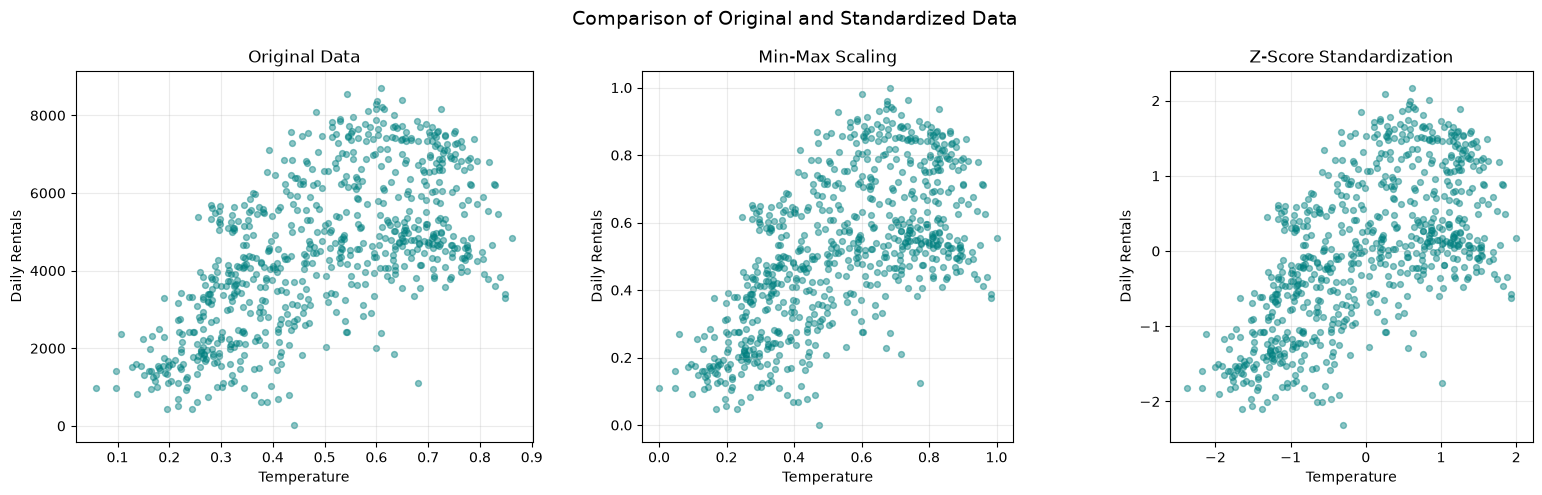

FINAL K-MEANS INPUT
Shape: (731, 2)
Columns: ['temp', 'cnt']
Missing values: 0


,temp,cnt
0,-0.826,-1.817
1,-0.721,-1.912
2,-1.634,-1.629
3,-1.614,-1.519
4,-1.466,-1.499


In [9]:

# Step 5.4: Compare the original and scaled feature spaces

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

datasets = [
    (cluster_features, "Original Data"),
    (minmax_data, "Min-Max Scaling"),
    (zscore_data, "Z-Score Standardization")
]

for ax, (data, title) in zip(axes, datasets):

    ax.scatter(
        data["temp"],
        data["cnt"],
        color="teal",
        alpha=0.45,
        s=18
    )

    ax.set_title(title)
    ax.set_xlabel("Temperature")
    ax.set_ylabel("Daily Rentals")
    ax.grid(alpha=0.25)

# Use the same physical scaling on both axes
# for the two standardized plots.
axes[1].set_aspect("equal", adjustable="box")
axes[2].set_aspect("equal", adjustable="box")

plt.suptitle(
    "Comparison of Original and Standardized Data",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Prepare the final input dataset for Preethi
X_scaled = zscore_data.copy()

print("FINAL K-MEANS INPUT")
print("Shape:", X_scaled.shape)
print("Columns:", X_scaled.columns.tolist())
print("Missing values:", X_scaled.isna().sum().sum())

display(X_scaled.head())



### Comparison of Original and Standardized Data

We created three scatterplots to compare our original data, Min-Max scaled data, and Z-score standardized data.

### Original Data

The original scatterplot shows a generally positive relationship between temperature and daily bike rentals.

However, the numerical scales of our two variables are very different. Temperature values are less than 1, while daily rentals can reach several thousand.

This could cause rental counts to have much more influence on K-means distance calculations.

### Min-Max Scaling

After Min-Max scaling, both temperature and rental counts range from 0 to 1.

The general pattern of the data remains the same, but both features now use a common numerical range.

### Z-Score Standardization

After Z-score standardization, both variables have an average of approximately 0 and a standard deviation of 1.

Values below 0 are below their variable's average, while positive values are above the average.

The scatterplot still shows the same overall relationship, but the values are now measured in standard deviation units.

### Our Final Decision

We selected Z-score standardization for our main clustering analysis because both features have equal standard deviations after scaling.

This allows temperature and daily rentals to contribute to distance calculations on comparable scales.

Min-Max scaling also worked correctly and would be a reasonable alternative.

We have prepared a separate dataset called `X_scaled`, containing 731 observations and two standardized features, with no missing values.

This dataset will be used for K-means clustering in the next section.


In [10]:

# Step 5.5: Final data preparation and validation

# Keep a copy of the standardized features
X_scaled = zscore_data.copy()

# Check that our original and scaled datasets match
assert len(X_scaled) == len(bike_df)
assert X_scaled.shape[1] == 2
assert X_scaled.index.equals(bike_df.index)

# Check for missing and infinite values
assert X_scaled.notna().all().all()
assert np.isfinite(X_scaled.to_numpy()).all()

# Check the standardization results
assert np.allclose(X_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_scaled.std(), 1, atol=1e-10)

print("FINAL DATA VALIDATION PASSED")
print("-" * 40)

print("Total observations:", len(X_scaled))
print("Clustering features:", X_scaled.columns.tolist())
print("Missing values:", X_scaled.isna().sum().sum())
print("Data ready for K-means:", True)

print("\nFinal standardized dataset:")
display(X_scaled.head())


FINAL DATA VALIDATION PASSED
----------------------------------------
Total observations: 731
Clustering features: ['temp', 'cnt']
Missing values: 0
Data ready for K-means: True

Final standardized dataset:


,temp,cnt
0,-0.826,-1.817
1,-0.721,-1.912
2,-1.634,-1.629
3,-1.614,-1.519
4,-1.466,-1.499



## 6. Prepared Data for K-Means Clustering

### Final Data Preparation Summary

We have completed the data preparation for our K-means clustering analysis.

We started with 731 daily bike rental records from the UCI Bike Sharing Dataset.

We checked the dataset for missing values, duplicates, incorrect rental totals and invalid numerical ranges.

We also examined possible outliers using boxplots and the IQR method. No outliers were identified in our two selected features using the 1.5 × IQR rule.

### Selected Features

We selected two variables:

1. `temp` - Normalized temperature
2. `cnt` - Total daily bike rentals

These variables will help us group days based on their temperature and rental demand.

### Standardization

We compared Min-Max scaling and Z-score standardization.

Both methods successfully scaled our data.

We selected Z-score standardization for our main analysis because it gives both variables a mean of 0 and a standard deviation of 1.

### Final Dataset

Our final dataset is stored in `X_scaled`.

- Observations: 731
- Features: 2
- Missing values: 0
- Infinite values: 0

We also kept `bike_df`, which contains the full prepared dataset, so we can use additional columns when describing the final clusters.

### Next Step: K-Means Clustering

The next step is to use `X_scaled` to run the K-means algorithm.

We will compare different numbers of clusters, examine their centres and sizes, create an elbow chart, and select a suitable final number of clusters based on the results.

We will not decide the final number of clusters before evaluating the different options.


## 7. K-Means Clustering Implementation

In this section, we apply K-Means clustering to our standardized temperature (`temp`) and total daily rentals (`cnt`) data.

We will test K values from 1 to 7 to see how the data is grouped with different numbers of clusters.

We will use the same K-Means settings as the professor's demonstration to keep our analysis consistent.

After running the models, we will compare their results using the elbow method, silhouette scores and cluster visualizations before selecting the final K.

In [11]:

# Step 7.1: Run K-Means for different K values

# Use the standardized dataset prepared by Person 1
X = X_scaled.copy()

# Store the models and their within-cluster sums of squares
kmeans_models = {}
wcss_values = []

# Try K values from 1 through 7
for k in range(1, 8):

    model = KMeans(
        n_clusters=k,
        max_iter=10,
        n_init=10,
        random_state=123
    )

    # Train the model using the standardized data
    model.fit(X)

    # Save the trained model
    kmeans_models[k] = model

    # Save within-cluster sum of squares (WCSS)
    wcss_values.append(model.inertia_)

    print(f"K = {k}, WCSS = {model.inertia_:.3f}")

print("\nAll K-Means models trained successfully.")


K = 1, WCSS = 1460.000
K = 2, WCSS = 570.174
K = 3, WCSS = 408.771
K = 4, WCSS = 270.484
K = 5, WCSS = 219.849
K = 6, WCSS = 186.443
K = 7, WCSS = 159.313

All K-Means models trained successfully.


## 8. Elbow Method for Selecting K

We used the elbow method to compare K-Means models with different numbers of clusters.

The elbow method uses the Within-Cluster Sum of Squares (WCSS) to measure how closely the observations are grouped around their cluster centres.

A lower WCSS means the observations are closer to their assigned centres. However, WCSS generally decreases as K increases, so we need to look for the point where adding more clusters gives only a smaller improvement.

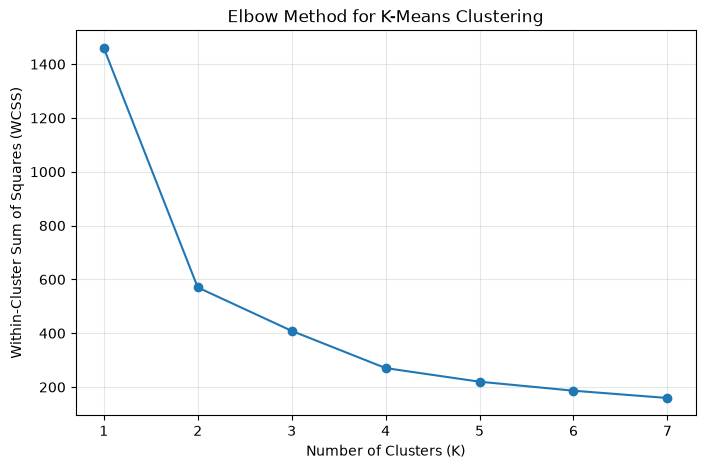

In [12]:

#  Plot the elbow chart

import matplotlib.pyplot as plt

k_values = list(range(1, 8))

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    wcss_values,
    marker='o',
    linestyle='-'
)

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)

plt.show()


### Elbow Chart Observations

From the elbow chart, we can see that the WCSS decreases as we increase the number of clusters.

The biggest drop is from K = 1 to K = 2, where the WCSS decreases from 1460.000 to 570.174. It continues to decrease for K = 3 and K = 4.

After K = 4, the line starts to become flatter, which means adding more clusters does not reduce the WCSS as much as before.

Based on the graph, we think **K = 4 could be a good choice**. However, the elbow is not very clear, so we will also check the silhouette scores and scatterplots before making our final decision.

## 9. Silhouette Score Analysis

After checking the elbow chart, we used silhouette scores to understand how well the data points are grouped.

The silhouette score checks whether data points are closer to their own cluster compared to other clusters. A higher score generally means the clusters are more clearly separated.

We calculated silhouette scores for K = 2 to K = 7. We did not include K = 1 because at least two clusters are needed to calculate the silhouette score.

We will compare these scores with the elbow chart and scatterplots before choosing the final K.

In [13]:

#  Calculate silhouette scores for K = 2 to 7

from sklearn.metrics import silhouette_score
import pandas as pd

silhouette_results = []

for k in range(2, 8):
    model = kmeans_models[k]
    labels = model.labels_

    score = silhouette_score(X, labels)

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

print("Silhouette Score Analysis")
display(silhouette_df.round(4))


Silhouette Score Analysis


,K,Silhouette Score
0,2,0.505
1,3,0.404
2,4,0.430
3,5,0.404
4,6,0.410
5,7,0.375


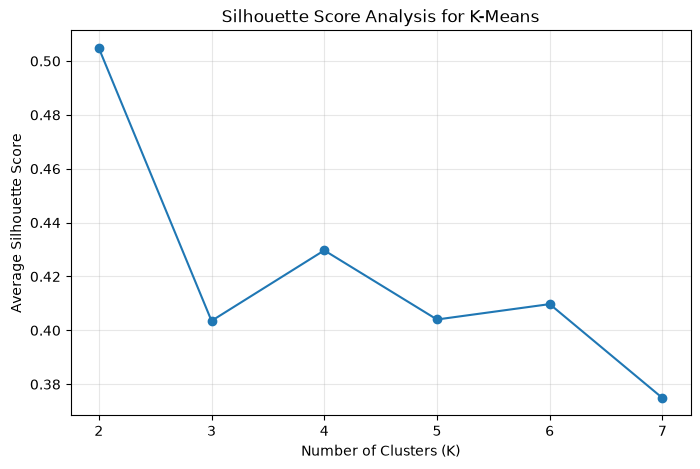

In [14]:

# Silhouette score line chart

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score Analysis for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.xticks(range(2, 8))
plt.grid(True, alpha=0.3)

plt.show()


### Silhouette Score Observations

From the silhouette score results, we can see that K = 2 has the highest score of 0.5048. This means that using two clusters gives better separation compared to the other K values we tested.

K = 4 has the second-highest score of 0.4297, while K = 7 has the lowest score of 0.3749.

When we compare this with the elbow chart, we notice that the elbow chart suggests K = 4 as a possible choice, but the silhouette score supports K = 2.

Since both methods suggest different K values, we will compare the cluster sizes and scatterplots before selecting the final number of clusters.

## 10. Cluster Visualization and Comparison

Based on the elbow chart and silhouette scores, we selected K = 2 and K = 4 for further comparison.

We will create scatterplots using the standardized temperature and total rental values to see how the observations are grouped.

We will also compare the cluster sizes to understand whether the groups are reasonably distributed.

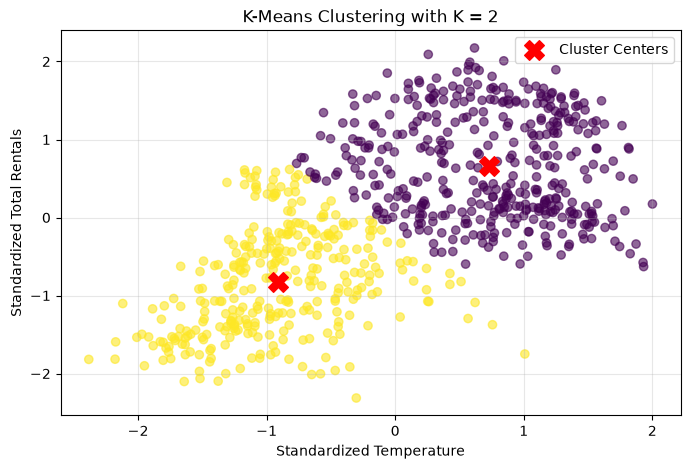

Cluster Sizes for K = 2
[407 324]
-----------------------------------


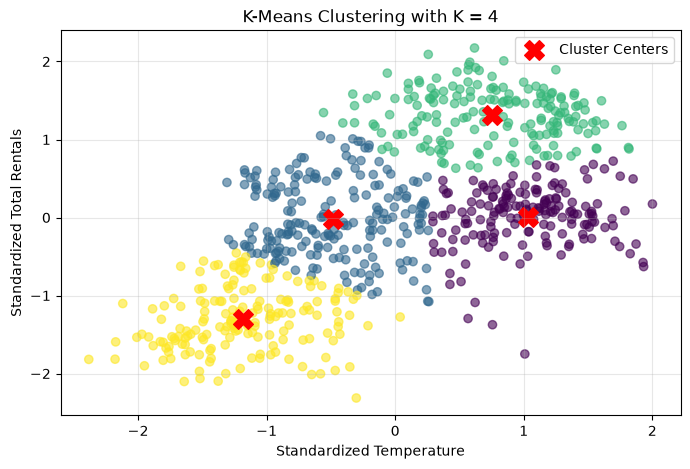

Cluster Sizes for K = 4
[169 205 179 178]
-----------------------------------


In [15]:

# Step 10.1: Compare K = 2 and K = 4

import numpy as np
import matplotlib.pyplot as plt

for k in [2, 4]:

    model = kmeans_models[k]
    labels = model.labels_
    centers = model.cluster_centers_

    plt.figure(figsize=(8, 5))

    plt.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=labels,
        cmap="viridis",
        alpha=0.6
    )

    plt.scatter(
        centers[:, 0],
        centers[:, 1],
        c="red",
        marker="X",
        s=200,
        label="Cluster Centers"
    )

    plt.title(f"K-Means Clustering with K = {k}")
    plt.xlabel("Standardized Temperature")
    plt.ylabel("Standardized Total Rentals")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    print(f"Cluster Sizes for K = {k}")
    print(np.bincount(labels))
    print("-" * 35)


### Cluster Visualization Observations

We compared K = 2 and K = 4 using scatterplots and cluster sizes.

**K = 2:**

The scatterplot shows two main groups. One group mostly contains days with lower temperatures and lower bike rentals, while the other group mostly contains days with higher temperatures and higher rentals.

The cluster sizes are 407 and 324, so both groups contain a good number of observations.

**K = 4:**

When we use four clusters, the data is divided into smaller groups. We can see differences between days with low, moderate and high rental demand at different temperatures.

The cluster sizes are 169, 205, 179 and 178. These sizes are fairly balanced, and there are no very small clusters.

**Comparison:**

K = 2 has the highest silhouette score of 0.5048, while K = 4 has a score of 0.4297.

K = 4 gives us more detailed groups, but K = 2 has better separation based on the silhouette score.

We will consider these results along with the elbow chart and the usefulness of the clusters before choosing the final K.

### 11. Compare Cluster Centres and Sizes

we will examine the cluster centres to understand the average temperature and rental demand within each cluster.

Since the data was standardized, positive values indicate above-average values and negative values indicate below-average values.

In [16]:

# Step 11.1: Display cluster centres and sizes for K = 2 and K = 4

import pandas as pd
import numpy as np

for k in [2, 4]:

    model = kmeans_models[k]

    # Get the cluster centres
    centers_df = pd.DataFrame(
        model.cluster_centers_,
        columns=[
            "Standardized Temperature",
            "Standardized Total Rentals"
        ]
    )

    # Count the number of days in each cluster
    centers_df["Number of Days"] = np.bincount(
        model.labels_,
        minlength=k
    )

    centers_df.index.name = "Cluster"

    print(f"\nCluster Centres and Sizes for K = {k}")
    display(centers_df.round(3))



Cluster Centres and Sizes for K = 2


,Standardized Temperature,Standardized Total Rentals,Number of Days
Cluster,,,
0,0.728,0.663,407
1,-0.914,-0.833,324



Cluster Centres and Sizes for K = 4


,Standardized Temperature,Standardized Total Rentals,Number of Days
Cluster,,,
0,1.033,0.009,169
1,-0.484,-0.018,205
2,0.755,1.309,179
3,-1.184,-1.304,178


### Cluster Centres and Sizes — Observations

We compared the cluster centres and sizes for K = 2 and K = 4.

**For K = 2**, the data is divided into two main groups. Cluster 0 contains 407 days with above-average temperatures and rentals, while Cluster 1 contains 324 days with below-average temperatures and rentals.

**For K = 4**, we can see more detailed groups:

- Cluster 0 has higher temperatures but rentals close to the average.
- Cluster 1 has lower temperatures with rentals close to the average.
- Cluster 2 has higher temperatures and much higher rentals.
- Cluster 3 has lower temperatures and much lower rentals.

The four cluster sizes are 169, 205, 179 and 178 days, so the observations are fairly balanced between the groups.

From these results, we can see that K = 4 gives us more detailed information about temperature and bike rental demand. We will use this along with our other evaluation results when deciding the final K.

## 12. Total, Within-Cluster and Between-Cluster Sums of Squares

We calculated TSS, WCSS and BCSS to understand how the variation in our data changes with different numbers of clusters.

TSS represents the total variation in the dataset. WCSS measures the variation within the clusters, and BCSS measures the variation between the cluster centres.

We will compare these values for K = 1 to K = 7 to understand how the clustering results change.

In [17]:

# Step 12.1: Calculate TSS, WCSS and BCSS

import numpy as np
import pandas as pd

# Calculate the total variation in standardized data
X_array = np.asarray(X)
overall_mean = X_array.mean(axis=0)

tss = np.sum((X_array - overall_mean) ** 2)

ss_results = []

for k in range(1, 8):

    model = kmeans_models[k]

    # Variation within clusters
    wcss = model.inertia_

    # Variation between clusters
    bcss = tss - wcss

    ss_results.append({
        "K": k,
        "TSS": tss,
        "WCSS": wcss,
        "BCSS": bcss,
        "BCSS (%)": (bcss / tss) * 100
    })

ss_df = pd.DataFrame(ss_results)

print("Sum of Squares Analysis")
display(ss_df.round(3))


Sum of Squares Analysis


,K,TSS,WCSS,BCSS,BCSS (%)
0,1,1460.000,1460.000,-0.000,-0.000
1,2,1460.000,570.174,889.826,60.947
2,3,1460.000,408.771,1051.229,72.002
3,4,1460.000,270.484,1189.516,81.474
4,5,1460.000,219.849,1240.151,84.942
5,6,1460.000,186.443,1273.557,87.230
6,7,1460.000,159.313,1300.687,89.088


### Sum of Squares Observations

From the results, we can see that TSS remains the same at 1460 for all K values because we are using the same standardized dataset.

As K increases, WCSS decreases and BCSS increases. This means the observations are grouped more closely around their cluster centres when we create more clusters.

For K = 2, the BCSS percentage is 60.95%, while for K = 4, it increases to 81.47%.

When we increase K from 4 to 5, the BCSS percentage only increases to 84.94%, which is a smaller improvement.

Based on these results, K = 4 looks like a reasonable choice because it gives us more detailed clusters without increasing the number of groups too much.

However, we will also consider the silhouette scores and how meaningful the clusters are before making our final recommendation.

## 13. Final K Selection and Recommendation

After comparing the elbow chart, silhouette scores, scatterplots and cluster sizes, we decided to use **K = 4** for our final clustering analysis.

The elbow chart shows that the WCSS starts to decrease more slowly after K = 4. At K = 4, the WCSS is 270.484, and the BCSS percentage is 81.47%.

The silhouette score is highest for K = 2 at 0.5048, while K = 4 has a score of 0.4297. This means K = 2 has better cluster separation based on the silhouette score.

However, we chose K = 4 because it gives us more detailed groups based on temperature and bike rental demand. For example, we can identify days with higher temperatures but average rentals, as well as days with higher temperatures and much higher rentals.

The four cluster sizes are 169, 205, 179 and 178, so the groups are also fairly balanced.

Overall, we feel K = 4 is more useful for understanding different bike rental demand patterns, even though K = 2 has a higher silhouette score.

In [18]:

# Step 13.1: Save the final K-Means clustering results

final_k = 4

# Reuse the existing trained model
final_model = kmeans_models[final_k]

# Get the cluster assignments for all 731 observations
final_labels = final_model.labels_

# Display the final cluster sizes
print("Final Selected K:", final_k)
print("Number of Observations:", len(final_labels))

print("\nCluster Sizes:")
print(pd.Series(final_labels).value_counts().sort_index())


Final Selected K: 4
Number of Observations: 731

Cluster Sizes:
0    169
1    205
2    179
3    178
Name: count, dtype: int64


## 14. Final Cluster Profiles and Interpretation

We selected four clusters for our final analysis. In this section, we
attach each day's cluster label to the complete cleaned dataset.

This allows us to compare rental demand, temperature, humidity,
working days, seasons and other available information across clusters.

Only temperature and total rentals were used to create the clusters.
The other variables help us describe and understand the groups.

In [19]:
# Attach final cluster labels to the complete cleaned dataset

# Confirm that labels and data refer to the same observations
assert len(final_labels) == len(X)
assert X.index.equals(bike_df.index)

# Keep all original cleaned columns
clustered_df = bike_df.copy()

# Use the model input index to align labels with the correct rows
clustered_df["Cluster"] = pd.Series(
    final_labels,
    index=X.index
)

# Check that every observation received a valid cluster label
assert clustered_df["Cluster"].notna().all()
assert clustered_df["Cluster"].nunique() == final_k
assert len(clustered_df) == len(bike_df)

print("Cluster labels added successfully.")
print("Total observations:", len(clustered_df))
print("Number of clusters:", clustered_df["Cluster"].nunique())

display(
    clustered_df[
        [
            "dteday",
            "Season_Name",
            "temp",
            "cnt",
            "hum",
            "workingday",
            "Cluster"
        ]
    ].head(10)
)

Cluster labels added successfully.
Total observations: 731
Number of clusters: 4


,dteday,Season_Name,temp,cnt,hum,workingday,Cluster
0,2011-01-01,Winter,0.344,985,0.806,0,3
1,2011-01-02,Winter,0.363,801,0.696,0,3
2,2011-01-03,Winter,0.196,1349,0.437,1,3
3,2011-01-04,Winter,0.200,1562,0.590,1,3
4,2011-01-05,Winter,0.227,1600,0.437,1,3
5,2011-01-06,Winter,0.204,1606,0.518,1,3
6,2011-01-07,Winter,0.197,1510,0.499,1,3
7,2011-01-08,Winter,0.165,959,0.536,0,3
8,2011-01-09,Winter,0.138,822,0.434,0,3
9,2011-01-10,Winter,0.151,1321,0.483,1,3


## 15. Cluster Sizes and Descriptive Statistics

We will count how many days belong to each cluster and calculate
the percentage of the dataset represented by each group.

We will also compare rental counts, temperature, humidity and
working days. These summaries help us understand how the groups differ.

For working days, the mean multiplied by 100 gives the percentage
of days classified as working days within each cluster.

In [20]:
# Group the complete dataset by its final cluster labels
cluster_groups = clustered_df.groupby("Cluster", sort=True)

# 1. Calculate cluster sizes and percentages
cluster_sizes = cluster_groups.size().to_frame("Number_of_Days")

cluster_sizes["Percentage_of_Days"] = (
    cluster_sizes["Number_of_Days"] / len(clustered_df) * 100
)

print("CLUSTER SIZES")
display(cluster_sizes.round(2))

# 2. Create a compact comparison of the main variables
cluster_summary = cluster_groups.agg(
    Number_of_Days=("cnt", "size"),
    Mean_Rentals=("cnt", "mean"),
    Median_Rentals=("cnt", "median"),
    Mean_Normalized_Temperature=("temp", "mean"),
    Mean_Normalized_Humidity=("hum", "mean"),
    Working_Day_Percentage=("workingday", lambda x: x.mean() * 100)
)

print("\nMAIN CLUSTER SUMMARY")
display(cluster_summary.round(3))

# 3. Show more detailed descriptive statistics
cluster_statistics = cluster_groups[
    ["cnt", "temp", "hum"]
].agg(["mean", "median", "std", "min", "max"])

print("\nDETAILED DESCRIPTIVE STATISTICS")
display(cluster_statistics.round(3))

# Confirm that all days are included
assert cluster_sizes["Number_of_Days"].sum() == len(clustered_df)

CLUSTER SIZES


,Number_of_Days,Percentage_of_Days
Cluster,,
0,169,23.120
1,205,28.040
2,179,24.490
3,178,24.350



MAIN CLUSTER SUMMARY


,Number_of_Days,Mean_Rentals,Median_Rentals,Mean_Normalized_Temperature,Mean_Normalized_Humidity,Working_Day_Percentage
Cluster,,,,,,
0,169,4521.533,4634.000,0.685,0.673,71.598
1,205,4469.834,4363.000,0.407,0.621,70.732
2,179,7040.128,7040.000,0.634,0.613,69.274
3,178,1977.758,1935.500,0.279,0.608,61.798



DETAILED DESCRIPTIVE STATISTICS


cnt                               temp                           \
            mean   median     std   min   max  mean median   std   min   max   
Cluster                                                                        
0       4521.533 4634.000 739.349  1115  5905 0.685  0.682 0.075 0.549 0.862   
1       4469.834 4363.000 936.312  2416  6536 0.407  0.403 0.078 0.256 0.543   
2       7040.128 7040.000 651.836  5728  8714 0.634  0.636 0.096 0.393 0.828   
3       1977.758 1935.500 772.551    22  3624 0.279  0.274 0.083 0.059 0.502   

          hum                           
         mean median   std   min   max  
Cluster                                 
0       0.673  0.688 0.134 0.305 0.972  
1       0.621  0.620 0.141 0.276 0.950  
2       0.613  0.620 0.110 0.254 0.844  
3       0.608  0.588 0.170 0.000 0.970

## 16. Cluster Centres on the Original Feature Scales

Our K-means model used Z-score standardized temperature and rental
counts. We will reverse this transformation to make the cluster
centres easier to interpret.

Original value = (standardized value × original standard deviation)
                 + original mean

We use the same means and standard deviations used during preparation.

Rental centres will represent daily rental counts. Temperature centres
will return to the dataset's original normalized scale, not Celsius.

In [21]:
# Convert the final cluster centres back to the original feature scales

# Preserve the feature order used to train the model
feature_columns = X.columns.tolist()

standardized_centres = pd.DataFrame(
    final_model.cluster_centers_,
    columns=feature_columns
)
standardized_centres.index.name = "Cluster"

# Use the same sample standard deviation as our original Z-score formula
original_means = cluster_features[feature_columns].mean()
original_stds = cluster_features[feature_columns].std(ddof=1)

original_centres = (
    standardized_centres * original_stds + original_means
)

# Add sizes to make interpretation easier
centres_summary = original_centres.rename(
    columns={
        "temp": "Centre_Normalized_Temperature",
        "cnt": "Centre_Daily_Rentals"
    }
).join(cluster_sizes)

print("FINAL CLUSTER CENTRES ON THE ORIGINAL FEATURE SCALES")
display(centres_summary.round(3))

# Compare model centres with the actual means of assigned observations
assigned_means = (
    clustered_df.groupby("Cluster")[feature_columns]
    .mean()
    .reindex(original_centres.index)
)

print("\nDIFFERENCE BETWEEN MODEL CENTRES AND ASSIGNED CLUSTER MEANS")
display((original_centres - assigned_means).round(6))

FINAL CLUSTER CENTRES ON THE ORIGINAL FEATURE SCALES


,Centre_Normalized_Temperature,Centre_Daily_Rentals,Number_of_Days,Percentage_of_Days
Cluster,,,,
0,0.685,4521.533,169,23.119
1,0.407,4469.834,205,28.044
2,0.634,7040.128,179,24.487
3,0.279,1977.758,178,24.350



DIFFERENCE BETWEEN MODEL CENTRES AND ASSIGNED CLUSTER MEANS


,temp,cnt
Cluster,,
0,0.000,0.000
1,0.000,0.000
2,-0.000,-0.000
3,0.000,0.000


## 17. Comparison of Key Characteristics Across Clusters

We will compare average daily rentals, normalized temperature,
humidity and the percentage of working days in each cluster.

Separate charts are used because these variables have different scales.
Humidity is converted from a proportion to a percentage.

Temperature and rental counts defined the clusters, so differences in
these variables are expected. Humidity and working-day percentages
provide additional information about the groups.

         Mean_Rentals  Mean_Normalized_Temperature  Mean_Humidity_Percentage  Working_Day_Percentage
Cluster                                                                                             
0            4521.533                        0.685                    67.301                  71.598
1            4469.834                        0.407                    62.129                  70.732
2            7040.128                        0.634                    61.265                  69.274
3            1977.758                        0.279                    60.799                  61.798


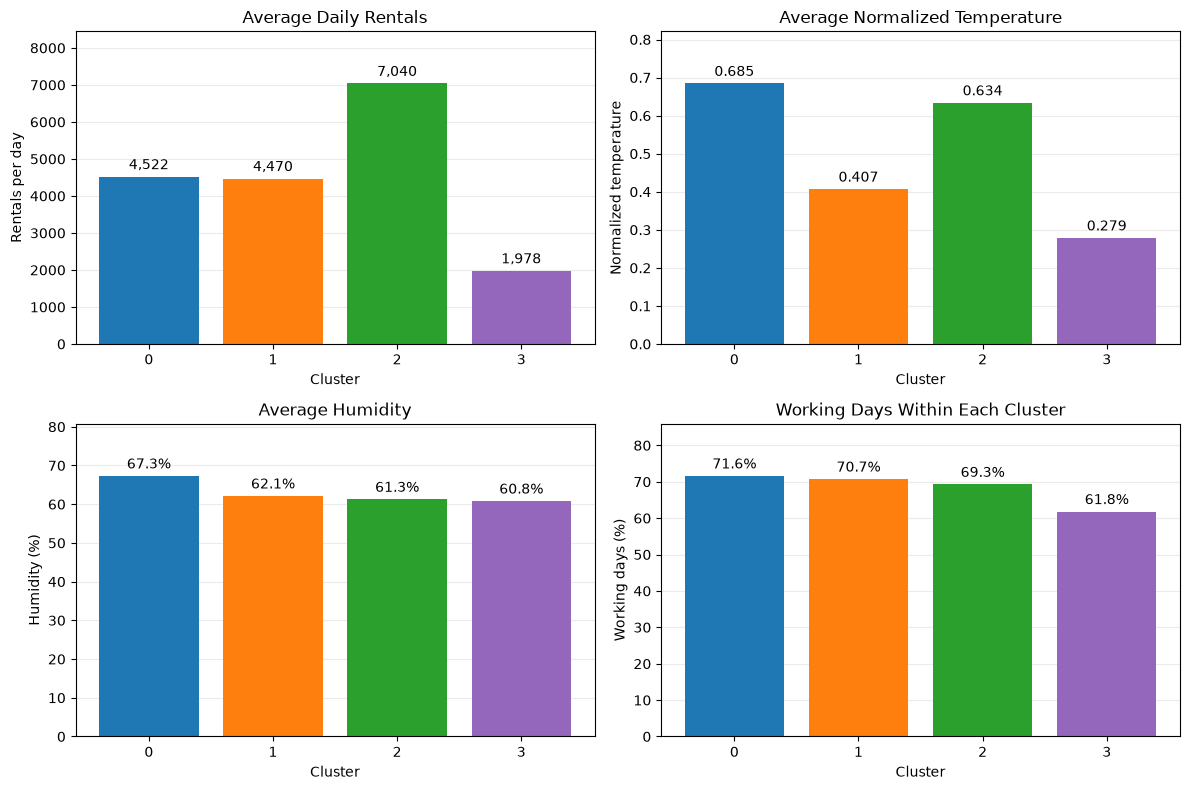

In [22]:
# Create a readable comparison table
cluster_comparison = cluster_summary[
    [
        "Mean_Rentals",
        "Mean_Normalized_Temperature",
        "Mean_Normalized_Humidity",
        "Working_Day_Percentage"
    ]
].copy()

# Convert normalized humidity to percentage
cluster_comparison["Mean_Humidity_Percentage"] = (
    cluster_comparison.pop("Mean_Normalized_Humidity") * 100
)

# Arrange columns for presentation
cluster_comparison = cluster_comparison[
    [
        "Mean_Rentals",
        "Mean_Normalized_Temperature",
        "Mean_Humidity_Percentage",
        "Working_Day_Percentage"
    ]
]

# Print all columns without horizontal scrolling
print(cluster_comparison.round(3).to_string())

# Plot each variable separately
plot_settings = [
    ("Mean_Rentals", "Average Daily Rentals", "Rentals per day"),
    (
        "Mean_Normalized_Temperature",
        "Average Normalized Temperature",
        "Normalized temperature"
    ),
    (
        "Mean_Humidity_Percentage",
        "Average Humidity",
        "Humidity (%)"
    ),
    (
        "Working_Day_Percentage",
        "Working Days Within Each Cluster",
        "Working days (%)"
    )
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
cluster_colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple"]

for ax, (column, title, ylabel) in zip(axes.flat, plot_settings):
    values = cluster_comparison[column]

    bars = ax.bar(
        values.index.astype(str),
        values,
        color=cluster_colors
    )

    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.2)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    labels = [
        f"{value:,.0f}" if column == "Mean_Rentals"
        else f"{value:.3f}" if column == "Mean_Normalized_Temperature"
        else f"{value:.1f}%"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=3)

plt.tight_layout()
plt.show()

### Interpretation of Cluster Comparisons

Cluster 0 has the highest average normalized temperature (0.685)
and humidity (67.3%), with approximately 4,522 rentals per day.

Cluster 1 has a lower average temperature (0.407), but a similar
rental average of approximately 4,470 per day. This shows that groups
with different temperatures can still have similar rental demand.

Cluster 2 has the highest average demand, with approximately 7,040
rentals per day. Its average normalized temperature is 0.634,
which is lower than Cluster 0. Therefore, the warmest group does
not have the highest rental demand.

Cluster 3 has the lowest average temperature (0.279) and rental
demand, with approximately 1,978 rentals per day.

Working days represent approximately 69–72% of days in Clusters
0, 1 and 2, compared with 61.8% in Cluster 3. These percentages
describe the composition of each cluster; they do not establish
that working-day status causes differences in demand.

Temperature and rentals were used to form the clusters, so their
differences are expected. Humidity and working-day percentages
provide additional context, but these comparisons do not prove
cause-and-effect relationships.

## 18. Seasonal Breakdown of Clusters

We will examine how Winter, Spring, Summer and Fall are distributed
across our four clusters.

We will calculate season counts and percentages within each cluster.
Each percentage row will total 100%.

This helps us identify whether a cluster mainly represents one
season or contains days from several seasons.

In [23]:
# Count days from each season within each cluster
season_order = ["Winter", "Spring", "Summer", "Fall"]

season_counts = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["Season_Name"]
).reindex(
    index=cluster_sizes.index,
    columns=season_order,
    fill_value=0
)

# Calculate the seasonal composition of each cluster
season_percentages = season_counts.div(
    season_counts.sum(axis=1),
    axis=0
) * 100

print("SEASON COUNTS WITHIN EACH CLUSTER")
display(season_counts)

print("\nSEASON PERCENTAGES WITHIN EACH CLUSTER")
display(season_percentages.round(2))

# Check that all observations are included
assert season_counts.to_numpy().sum() == len(clustered_df)
assert np.array_equal(
    season_counts.sum(axis=1).to_numpy(),
    cluster_sizes["Number_of_Days"].to_numpy()
)
assert np.allclose(season_percentages.sum(axis=1), 100)

SEASON COUNTS WITHIN EACH CLUSTER


Season_Name,Winter,Spring,Summer,Fall
Cluster,,,,
0,0,53,102,14
1,46,50,4,105
2,6,58,82,33
3,129,23,0,26



SEASON PERCENTAGES WITHIN EACH CLUSTER


Season_Name,Winter,Spring,Summer,Fall
Cluster,,,,
0,0.000,31.360,60.360,8.280
1,22.440,24.390,1.950,51.220
2,3.350,32.400,45.810,18.440
3,72.470,12.920,0.000,14.610


### Interpretation of Seasonal Patterns

Cluster 0 mainly contains Summer days (60.36%), followed by
Spring days (31.36%). This supports its description as a warmer
group with moderate rental demand.

Cluster 1 mainly contains Fall days (51.22%), with additional
Spring and Winter days. It represents cooler days with moderate demand.

Cluster 2 contains mostly Summer (45.81%) and Spring (32.40%) days.
It has the highest average rental demand, although its days occur
across all four seasons.

Cluster 3 mainly contains Winter days (72.47%) and has no Summer
days. This agrees with its lower average temperature and rental demand.

The clusters do not exactly match seasons. For example, Summer days
appear in both moderate-demand and high-demand groups. Clustering
therefore provides more detail than grouping the data by season alone.

## 19. Descriptive Cluster Names

We named the clusters using their average temperatures and rental
counts. The names describe relative differences within our dataset.

- **Cluster 0 — Warm Days, Moderate Demand:** The warmest group,
  averaging approximately 4,522 rentals per day. Most days are in Summer.

- **Cluster 1 — Cool Days, Moderate Demand:** Lower temperatures,
  averaging approximately 4,470 rentals per day. Most days are in Fall.

- **Cluster 2 — Warm Days, High Demand:** Warm temperatures and the
  highest rental average, approximately 7,040 per day. Most days are
  in Spring or Summer.

- **Cluster 3 — Cold Days, Low Demand:** The lowest temperatures
  and rental average, approximately 1,978 per day. Most days are
  in Winter.

These names summarize the groups rather than define strict temperature
or rental thresholds. Individual days can differ from their cluster average.

In [24]:
# Give each cluster a descriptive name
cluster_names = {
    0: "Warm Days, Moderate Demand",
    1: "Cool Days, Moderate Demand",
    2: "Warm Days, High Demand",
    3: "Cold Days, Low Demand"
}

clustered_df["Cluster_Name"] = (
    clustered_df["Cluster"].map(cluster_names)
)

# Combine names, main characteristics and seasonal composition
named_cluster_summary = (
    cluster_sizes
    .join(cluster_comparison)
    .join(season_percentages.add_suffix("_Share_Percent"))
)

named_cluster_summary.insert(
    0,
    "Cluster_Name",
    named_cluster_summary.index.map(cluster_names)
)

assert clustered_df["Cluster_Name"].notna().all()

print("FINAL NAMED CLUSTER SUMMARY")
display(named_cluster_summary.round(2))

# Compact output for easier reading
print("\nCLUSTER NAMES AND AVERAGE RENTALS")
print(
    named_cluster_summary[
        ["Cluster_Name", "Number_of_Days", "Mean_Rentals"]
    ].round(2).to_string()
)

FINAL NAMED CLUSTER SUMMARY


,Cluster_Name,Number_of_Days,Percentage_of_Days,Mean_Rentals,Mean_Normalized_Temperature,Mean_Humidity_Percentage,Working_Day_Percentage,Winter_Share_Percent,Spring_Share_Percent,Summer_Share_Percent,Fall_Share_Percent
Cluster,,,,,,,,,,,
0,"Warm Days, Moderate Demand",169,23.120,4521.530,0.680,67.300,71.600,0.000,31.360,60.360,8.280
1,"Cool Days, Moderate Demand",205,28.040,4469.830,0.410,62.130,70.730,22.440,24.390,1.950,51.220
2,"Warm Days, High Demand",179,24.490,7040.130,0.630,61.270,69.270,3.350,32.400,45.810,18.440
3,"Cold Days, Low Demand",178,24.350,1977.760,0.280,60.800,61.800,72.470,12.920,0.000,14.610



CLUSTER NAMES AND AVERAGE RENTALS
                       Cluster_Name  Number_of_Days  Mean_Rentals
Cluster                                                          
0        Warm Days, Moderate Demand             169      4521.530
1        Cool Days, Moderate Demand             205      4469.830
2            Warm Days, High Demand             179      7040.130
3             Cold Days, Low Demand             178      1977.760


## 20. Practical Business Insights

### 1. Plan capacity for high-demand periods

Cluster 2 averages approximately 7,040 rentals per day, compared
with about 4,470–4,522 in the moderate-demand clusters.

This suggests that the company should investigate when these
high-demand conditions occur and prepare enough serviceable bikes
and operational staff. Station-level information would be needed
to decide where bikes should be placed.

### 2. Consider maintenance during lower-demand periods

Cluster 3 averages approximately 1,978 rentals per day, and 72.47%
of its days occur in Winter.

Historically quieter periods may provide opportunities for bike
repairs and inspections. The company should check current demand
before reducing available bikes or scheduling maintenance.

### 3. Avoid planning from temperature alone

Cluster 0 is the warmest group, but it averages approximately
4,522 rentals per day. Cluster 2 has a slightly lower average
temperature and approximately 7,040 rentals per day.

This shows that warmer conditions do not always correspond to
higher demand. Planning should also consider season, weather,
year and other relevant information.

### How These Insights Should Be Used

These findings describe historical groups and suggest planning
opportunities. They do not predict which cluster a future day will
belong to, because the clustering model uses that day's total rentals.
The proposed actions would need further validation before use.

## 21. Seasonal Composition of Clusters

This chart shows the percentage of days from each season within
each cluster.

Each bar represents one cluster and totals 100%. The coloured
sections represent Winter, Spring, Summer and Fall.

This helps us compare seasonal patterns across clusters of
different sizes.

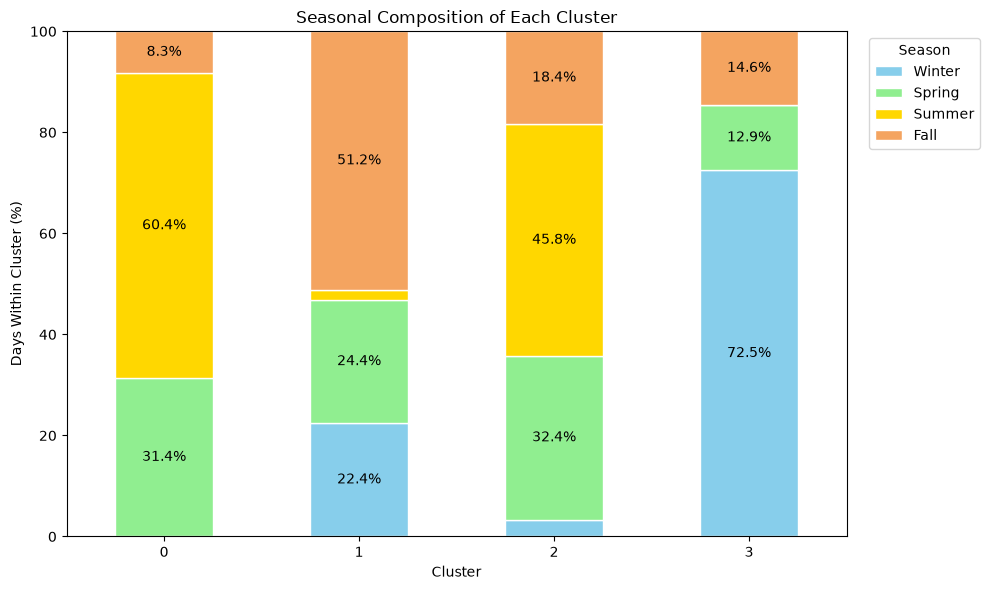

In [26]:
# Show the seasonal composition of each cluster
ax = season_percentages[
    ["Winter", "Spring", "Summer", "Fall"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["skyblue", "lightgreen", "gold", "sandybrown"],
    edgecolor="white",
    rot=0
)

# Display percentages inside larger sections
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 8 else ""
        for value in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=10
    )

ax.set_title("Seasonal Composition of Each Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Days Within Cluster (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Season",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Interpretation

- Cluster 0 mainly contains Summer days (60.36%).
- Cluster 1 mainly contains Fall days (51.22%).
- Cluster 2 contains mostly Summer (45.81%) and Spring (32.40%) days.
- Cluster 3 mainly contains Winter days (72.47%).

The clusters do not represent individual seasons exactly. For example,
Summer days appear in both Cluster 0 and Cluster 2, even though these
clusters have different average rental demand.

Small sections below 8% are shown without labels to keep the chart
readable. Their exact percentages are available in Section 18.

## 22. Limitations and Future Improvements

### Limitations

1. **Only two clustering features**
   We formed clusters using temperature and total rentals. Other
   factors, such as weather conditions and changes between years,
   may help explain the differences between groups.

2. **Historical data**
   Our dataset contains 731 days from 2011 and 2012. These patterns
   may not represent current bike-sharing demand or other locations.

3. **The number of clusters involves judgement**
   K = 2 had the highest silhouette score, but we selected K = 4
   for more detailed interpretation. Four clusters are a useful
   choice for our purpose, rather than the only correct answer.

4. **Clustering does not establish causes or predict demand**
   Temperature and rentals were used to create the groups, so
   differences in these variables are expected. We cannot conclude
   that temperature causes rental changes. The model also requires
   the day's rental total, so it cannot directly predict future demand.

5. **Daily totals hide local patterns**
   Daily data does not show hourly peaks or differences between
   rental stations. We cannot determine where or when additional
   bikes would be needed from this analysis alone.

### Future Improvements

- Compare cluster composition across 2011 and 2012 to investigate
  whether changes between years help explain demand differences.
- Describe clusters using additional columns, including wind speed,
  weather conditions, casual rentals and registered rentals.
- Repeat clustering with different random seeds and compare results
  to check whether the groups remain similar.
- Compare the results under Min-Max scaling and Z-score standardization.
- Use more recent, hourly and station-level data for operational planning.
- Develop a separate forecasting model using information available
  before the rental period if future demand prediction is required.

## 23. Final Conclusion

Our analysis identified four useful groups of bike-rental days
based on temperature and total daily rentals.

We checked all 731 records and standardized the two selected
features so their different numerical scales would not dominate
the distance calculations.

We compared different numbers of clusters using the elbow chart,
silhouette scores, scatterplots and cluster sizes. Although two
clusters had the highest silhouette score, we selected four
because they provided more detailed groups for interpretation.

The final groups were:

- Warm Days, Moderate Demand: approximately 4,522 rentals per day.
- Cool Days, Moderate Demand: approximately 4,470 rentals per day.
- Warm Days, High Demand: approximately 7,040 rentals per day.
- Cold Days, Low Demand: approximately 1,978 rentals per day.

The seasonal analysis showed that the cold, low-demand group
mainly contained Winter days. However, Summer days appeared in
both moderate-demand and high-demand groups. Therefore, the
clusters provide more detail than a comparison of seasons alone.

These findings suggest opportunities to investigate staffing,
bike availability and maintenance scheduling. They describe
historical patterns rather than predict future demand or prove
that temperature causes rental changes.

## 24. Five-Minute Presentation Guide

### 0:00–0:35 — Project Introduction
Show: Research Question

“Our project explores daily bike rental patterns using K-means
clustering. This method groups similar days without predefined labels.

We wanted to find groups based on temperature and rental demand,
then understand how these groups relate to seasons.”

### 0:35–1:15 — Data Preparation and Standardization
Show: Data Validation Summary and Scaling Comparison

“We used 731 daily records from 2011 and 2012. We checked missing
values, duplicates, rental totals and possible outliers.
Our checks did not require removing any rows.

We selected temperature and total daily rentals. Because rentals
are measured in thousands and normalized temperatures are below
one, we standardized both features using Z-scores. This puts
their differences on comparable scales.”

### 1:15–2:10 — Choosing the Number of Clusters
Show: Elbow Chart, Silhouette Results and K = 4 Scatterplot

“We tested one to seven clusters.

The elbow chart suggested four clusters as a reasonable option.
However, two clusters had the highest silhouette score, about
0.505, compared with 0.430 for four clusters.

We selected four because they provided more detailed groups.
They distinguish warm and cool days with moderate demand,
as well as high-demand and low-demand days.

Our choice balances cluster separation with useful detail.”

### 2:10–3:05 — Explain the Four Clusters
Show: Named Cluster Summary

“Cluster 0 represents warm days with moderate demand:
approximately 4,522 rentals per day.

Cluster 1 represents cool days with moderate demand:
approximately 4,470 rentals per day.

Cluster 2 represents warm days with high demand:
approximately 7,040 rentals per day.

Cluster 3 represents cold days with low demand:
approximately 1,978 rentals per day.

The warmest group does not have the highest demand.
This shows why temperature alone cannot explain rental patterns.”

### 3:05–3:45 — Seasonal Patterns
Show: Seasonal Stacked Bar Chart

“Each bar represents one cluster and totals 100%.
The colours show the seasons within that cluster.

Cluster 0 mainly contains Summer days, and Cluster 1 mainly
contains Fall days. Cluster 2 contains mostly Spring and Summer
days. About 72% of Cluster 3’s days occurred in Winter.

Summer appears in both moderate-demand and high-demand groups,
so clustering gives us more detail than seasons alone.”

### 3:45–4:25 — Business Insights
Show: Practical Business Insights

“We identified three possible business uses.

First, investigate high-demand periods to plan bike availability
and staffing.

Second, consider maintenance during historically quieter periods,
after checking current demand.

Third, consider several factors when planning, because the
warmest days do not always have the highest demand.

Station-level data would be needed to decide where bikes
should be placed.”

### 4:25–5:00 — Limitations and Conclusion
Show: Limitations and Final Conclusion

“Our dataset covers only two years, and we used two features
to form the clusters. More recent data and additional information
could help us understand the patterns better.

This analysis describes historical groups. It does not prove
causes or predict future demand.

Overall, we identified four understandable groups that reveal
differences beyond seasons alone and provide a starting point
for further business analysis.”